CREATE A MODEL WHICH PREDICTS WHETHER A PERSON HAVE HEART DISEASE 
I.E. DISEASE DECTION SYSTEM

In [75]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier 

warnings.filterwarnings('ignore')

In [76]:
df=pd.read_csv('heart.csv')

In [77]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [78]:
print(df.shape)
print(df.columns)

(918, 12)
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')


In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [80]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [81]:
df.duplicated().sum()
#no duplicate values

np.int64(0)

In [82]:
df['HeartDisease'].value_counts()

HeartDisease
1    508
0    410
Name: count, dtype: int64

<Axes: xlabel='HeartDisease'>

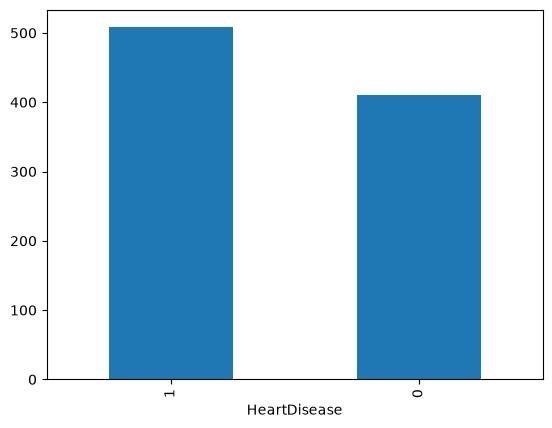

In [83]:
#creating plot of the above counts
df['HeartDisease'].value_counts().plot(kind='bar')

In [84]:
df.isnull().sum()
#no null values

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

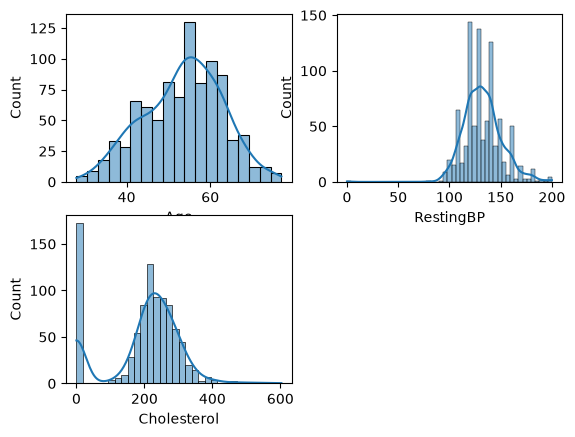

In [85]:
#creating distribution of numerical distribution
def plotting(var,num):
    plt.subplot(2,2,num) 
    sns.histplot(x=var,data=df,kde=True)

plotting('Age',1)
plotting('RestingBP',2)  #A living person cannot have a resting blood pressure (BP) of zero.
plotting('Cholesterol',3) #A person cannot have a cholesterol level of zero but 600 ho skta h 

In [86]:
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.2,
    random_state=42,
    stratify=df['HeartDisease']
)

In [87]:
# since a person cannot have a cholesterol level and resting bp of zero
# so we'll clean the data
ch_mean = df.loc[
    train_idx[ df.loc[train_idx, 'Cholesterol'] != 0 ],
    'Cholesterol'
].mean()
display(ch_mean)
#df['Cholesterol'] != 0 → sirf non-zero values ko select karega.
#df.loc[..., 'Cholesterol'] → un selected rows ka Cholesterol column lega.
#.mean() → un values ka average calculate karega.
df['Cholesterol']=df['Cholesterol'].replace(0,ch_mean)
df['Cholesterol']=df['Cholesterol'].round(2)#round of cholesterol value

np.float64(246.5603305785124)

In [88]:
rbp_mean = df.loc[
    train_idx[ df.loc[train_idx, 'RestingBP'] != 0 ],
    'RestingBP'
].mean()
display(rbp_mean)
df['RestingBP']=df['RestingBP'].replace(0,rbp_mean)
df['RestingBP']=df['RestingBP'].round(2)

np.float64(132.87465940054497)

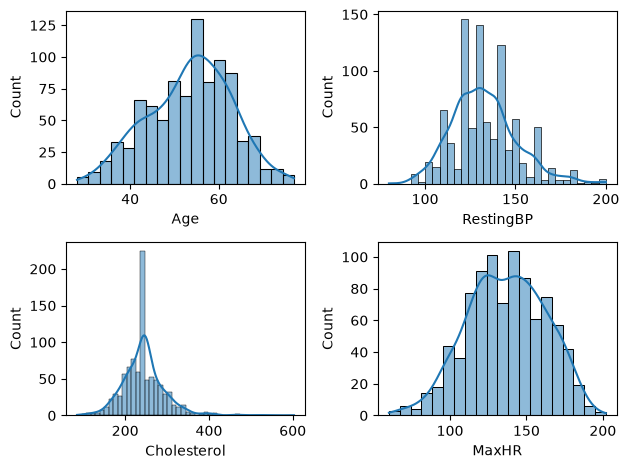

In [89]:
#checking the distribution again after cleaning the data
def plotting(var,num):
    plt.subplot(2,2,num) 
    sns.histplot(x=var,data=df,kde=True)

plotting('Age',1)
plotting('RestingBP',2)  
plotting('Cholesterol',3) 
plotting('MaxHR',4)

plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

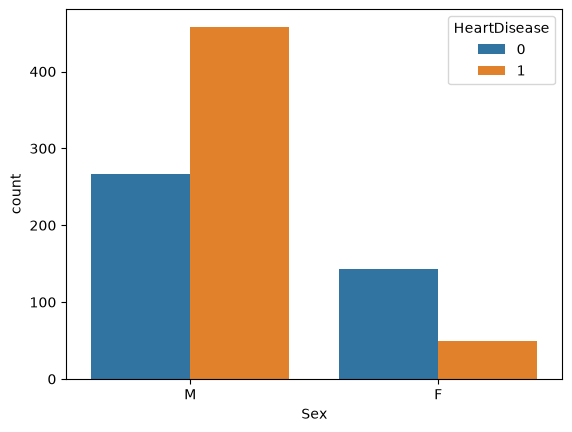

In [90]:
#  create a count plots for categorical values
sns.countplot(x='Sex',data=df,hue='HeartDisease')

<Axes: xlabel='ChestPainType', ylabel='count'>

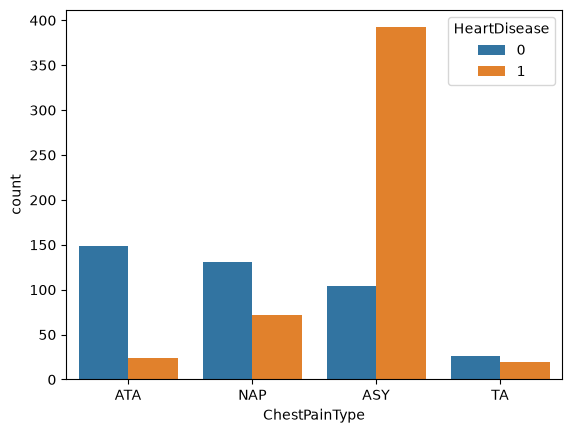

In [91]:
sns.countplot(x='ChestPainType',data=df,hue='HeartDisease')

<Axes: xlabel='FastingBS', ylabel='count'>

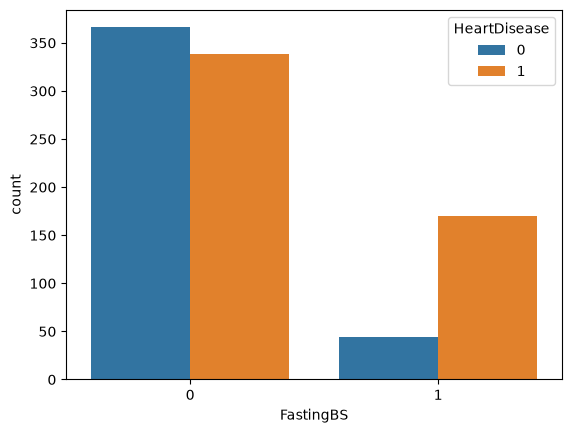

In [92]:
sns.countplot(x='FastingBS',data=df,hue='HeartDisease')

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

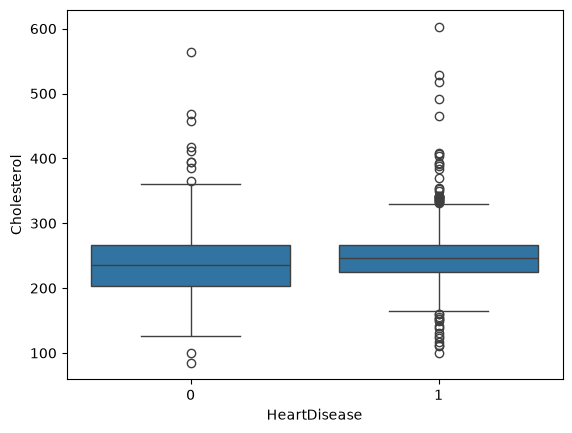

In [93]:
sns.boxplot(y='Cholesterol',data=df,x='HeartDisease')

<Axes: xlabel='HeartDisease', ylabel='Age'>

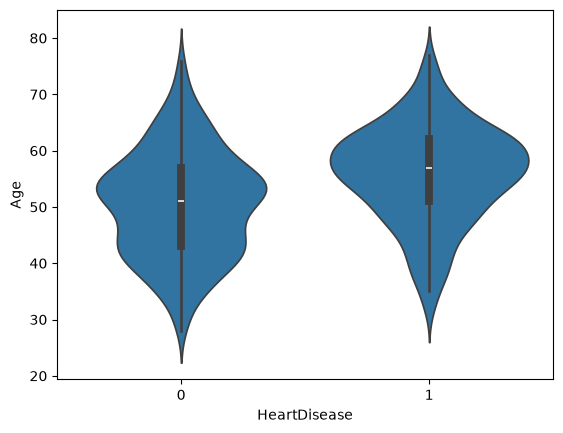

In [94]:
sns.violinplot(x='HeartDisease',y='Age',data=df)

<Axes: >

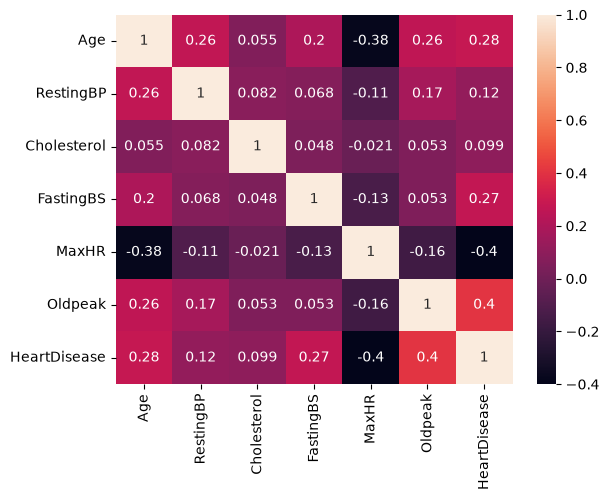

In [95]:
sns.heatmap(data=df.corr(numeric_only=True),annot=True)

#DATA PREPROCESSING N CLEANING


In [96]:
df_encode=pd.get_dummies(df)
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160.0,180.0,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130.0,283.0,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138.0,214.0,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150.0,195.0,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,False,True,False,...,False,True,False,True,False,True,False,False,True,False
914,68,144.0,193.0,1,141,3.4,1,False,True,True,...,False,False,False,True,False,True,False,False,True,False
915,57,130.0,131.0,0,115,1.2,1,False,True,True,...,False,False,False,True,False,False,True,False,True,False
916,57,130.0,236.0,0,174,0.0,1,True,False,False,...,False,False,True,False,False,True,False,False,True,False


In [97]:
dummy_cols = df_encode.select_dtypes(include='bool').columns

df_encode[dummy_cols] = df_encode[dummy_cols].astype(int)

df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140.0,289.0,0,172,0.0,0,0,1,0,...,0,0,0,1,0,1,0,0,0,1
1,49,160.0,180.0,0,156,1.0,1,1,0,0,...,1,0,0,1,0,1,0,0,1,0
2,37,130.0,283.0,0,98,0.0,0,0,1,0,...,0,0,0,0,1,1,0,0,0,1
3,48,138.0,214.0,0,108,1.5,1,1,0,1,...,0,0,0,1,0,0,1,0,1,0
4,54,150.0,195.0,0,122,0.0,0,0,1,0,...,1,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,0,1,0,...,0,1,0,1,0,1,0,0,1,0
914,68,144.0,193.0,1,141,3.4,1,0,1,1,...,0,0,0,1,0,1,0,0,1,0
915,57,130.0,131.0,0,115,1.2,1,0,1,1,...,0,0,0,1,0,0,1,0,1,0
916,57,130.0,236.0,0,174,0.0,1,1,0,0,...,0,0,1,0,0,1,0,0,1,0


In [98]:


x = df_encode.drop('HeartDisease', axis=1)
y = df_encode['HeartDisease']

x_train = x.loc[train_idx].copy()
x_test = x.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

In [99]:
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

ss = StandardScaler()

x_train[numeric_cols] = ss.fit_transform(x_train[numeric_cols])
x_test[numeric_cols] = ss.transform(x_test[numeric_cols])

In [100]:
cat_features = [
    'FastingBS', 'Sex_F', 'Sex_M',
    'ChestPainType_ATA', 'ChestPainType_ASY',
    'ChestPainType_NAP', 'ChestPainType_TA',
    'RestingECG_LVH', 'RestingECG_Normal',
    'RestingECG_ST', 'ExerciseAngina_N',
    'ExerciseAngina_Y', 'ST_Slope_Down',
    'ST_Slope_Flat', 'ST_Slope_Up'
]



alpha = 0.05
chi2_res = {}

for col in cat_features:

    contingency = pd.crosstab(
        x_train[col],
        y_train
    )

    chi2_stat, p_val, _, _ = chi2_contingency(contingency)

    decision = 'Significant (Keep Feature)' if p_val < alpha else 'Not Significant (Review Feature)'

    chi2_res[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'decision': decision
    }

chi2_df = pd.DataFrame(chi2_res).T
chi2_df = chi2_df.sort_values(by='p_value')

chi2_df

,chi2_statistic,p_value,decision
ST_Slope_Up,306.540813,0.0,Significant (Keep Feature)
ST_Slope_Flat,236.847596,0.0,Significant (Keep Feature)
ChestPainType_ASY,194.979122,0.0,Significant (Keep Feature)
ExerciseAngina_N,174.859118,0.0,Significant (Keep Feature)
ExerciseAngina_Y,174.859118,0.0,Significant (Keep Feature)
ChestPainType_ATA,113.387822,0.0,Significant (Keep Feature)
Sex_M,56.263232,0.0,Significant (Keep Feature)
Sex_F,56.263232,0.0,Significant (Keep Feature)
FastingBS,48.907227,0.0,Significant (Keep Feature)
ChestPainType_NAP,36.550016,0.0,Significant (Keep Feature)


In [101]:
models = {
    "Logistic Regression":LogisticRegression(),
    "KNN":KNeighborsClassifier(),
    "Naive Bayes":GaussianNB(),
    "Decision tree":DecisionTreeClassifier(),
    "SVM": SVC()
    }

In [102]:
res=[]

In [103]:
for name,model in models.items():
    model.fit(x_train,y_train)
    pred=model.predict(x_test)
    acc=accuracy_score(y_test,pred)
    f1=f1_score(y_test,pred)
    res.append({
        'model':name,
        'Accuracy':round(acc,4),
        'f1 score':round(f1,4)
    })

In [104]:
res

[{'model': 'Logistic Regression', 'Accuracy': 0.8967, 'f1 score': 0.9082},
 {'model': 'KNN', 'Accuracy': 0.8859, 'f1 score': 0.8955},
 {'model': 'Naive Bayes', 'Accuracy': 0.8696, 'f1 score': 0.8812},
 {'model': 'Decision tree', 'Accuracy': 0.7663, 'f1 score': 0.7839},
 {'model': 'SVM', 'Accuracy': 0.8696, 'f1 score': 0.8857}]

In [105]:
#for this model logistic regression is the best

In [106]:
#pickle file m save krege in order to use or deploy this model in frontend


joblib.dump(models['Logistic Regression'],'LOGREG_heart.pkl')



['LOGREG_heart.pkl']

In [107]:
joblib.dump(ss,'scaler.pkl')
joblib.dump(x.columns.tolist(),'columns.pkl')

['columns.pkl']